Loaded 35080 records from last 365 days
['Very Early', 'Slightly Early', 'On Time', 'Slightly Late', 'Late', 'Very Late']
[np.int64(3295), np.int64(14694), np.int64(4563), np.int64(4534), np.int64(3771), np.int64(3236)]


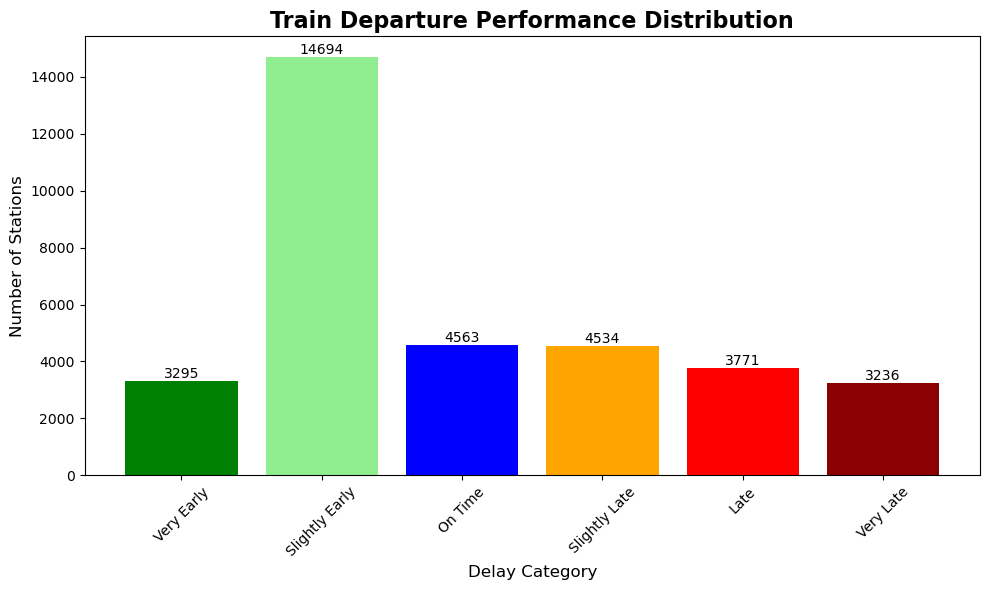

Very Early percentage: 9.7%
Slightly Early percentage: 43.1%
On Time percentage: 13.4%
Slightly Late percentage: 13.3%
Late percentage: 11.1%
Very Late percentage: 9.5%


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from automated_collection import HistoricalDataManager

historical_data_collector = HistoricalDataManager()


stations_df = historical_data_collector.get_historical_data(365)

# Data visualization from recent_data_visualiztion notebook.
plt.figure(figsize=(10, 6))
delay_bins = [-60, -5, 5, 15, 30, 60, 999]
delay_labels = ['Very Early', 'Slightly Early', 'On Time', 'Slightly Late', 'Late', 'Very Late']
delay_colors = ['green', 'lightgreen', 'blue', 'orange', 'red', 'darkred']
stations_df['delay_category'] = pd.cut(
  stations_df['departure_delay_minutes'], 
  bins=delay_bins, 
  labels=delay_labels
)
delay_counts = stations_df['delay_category'].value_counts()
ordered_categories = delay_labels
ordered_counts = [delay_counts.get(category, 0) for category in ordered_categories]

print(ordered_categories)
print(ordered_counts)
bars = plt.bar(ordered_categories, ordered_counts, color=delay_colors)
plt.title('Train Departure Performance Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Delay Category', fontsize=12)
plt.ylabel('Number of Stations', fontsize=12)
plt.xticks(rotation=45)
for bar, count in zip(bars, ordered_counts):
  x_position = bar.get_x() + bar.get_width()/2.
  y_position = count + 0.5
  plt.text(x_position, y_position, str(count), ha='center', va='bottom')

plt.tight_layout()
plt.show()

delay_counts_sum = delay_counts.sum()
for category, count in zip(ordered_categories, ordered_counts):
  print(f"{category} percentage: {round(count/delay_counts_sum*100,1)}%")


Showing 34 routes with significant delays (≥50 samples, |delay| > 5 min)

Most early routes:
                     mean  count
route_name                      
Cardinal        -9.895833    288
Amtrak Cascades  5.104723    487
Sunset Limited   6.372727    440

Most delayed routes:
                            mean  count
route_name                             
Niagara Falls-Toronto  51.500000     60
Canadian               57.726367   1634
Ocean                  84.542113    560


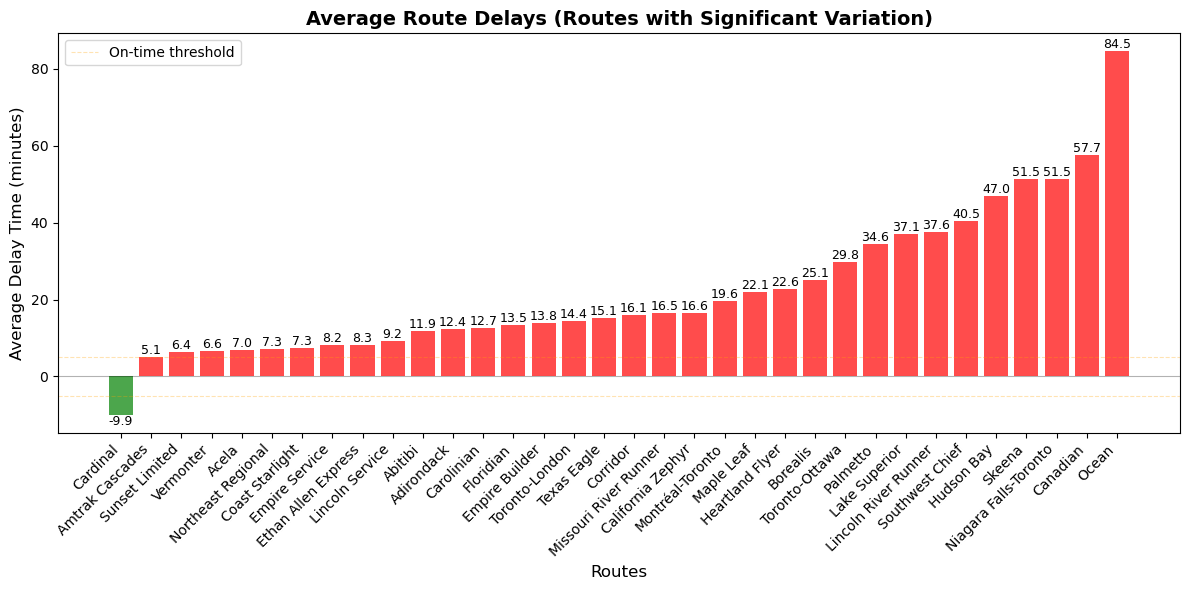


Summary:
Average delay across all filtered routes: 22.3 minutes
Most early route: Cardinal (-9.9 min)
Most delayed route: Ocean (84.5 min)


In [6]:
# Filter for routes with significant sample sizes and delays
route_delays = stations_df.groupby('route_name')['departure_delay_minutes'].agg(['mean', 'count'])

# Only show routes with at least 50 data points for statistical significance
route_delays = route_delays[route_delays['count'] >= 50]

# Only show routes with average delays outside "on-time" range (-5 to 5 minutes)
# This filters out routes that are essentially on time
route_delays = route_delays[(route_delays['mean'] < -5) | (route_delays['mean'] > 5)]

route_delays = route_delays.sort_values(by='mean')

print(f"Showing {len(route_delays)} routes with significant delays (≥50 samples, |delay| > 5 min)")
print(f"\nMost early routes:")
print(route_delays.head(3))
print(f"\nMost delayed routes:")
print(route_delays.tail(3))

# Create visualization
plt.figure(figsize=(12, 6))

# Color bars based on delay (red for late, green for early)
colors = ['green' if x < 0 else 'red' for x in route_delays['mean']]

bars = plt.bar(route_delays.index, route_delays['mean'], color=colors, alpha=0.7)

plt.title('Average Route Delays (Routes with Significant Variation)', fontsize=14, fontweight='bold')
plt.xlabel('Routes', fontsize=12)
plt.ylabel('Average Delay Time (minutes)', fontsize=12)
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.8, alpha=0.3)
plt.axhline(y=5, color='orange', linestyle='--', linewidth=0.8, alpha=0.3, label='On-time threshold')
plt.axhline(y=-5, color='orange', linestyle='--', linewidth=0.8, alpha=0.3)

# Rotate labels for readability
plt.xticks(rotation=45, ha='right')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.1f}',
             ha='center', va='bottom' if height > 0 else 'top',
             fontsize=9)

plt.legend()
plt.tight_layout()
plt.show()

# Summary statistics
print(f"\nSummary:")
print(f"Average delay across all filtered routes: {route_delays['mean'].mean():.1f} minutes")
print(f"Most early route: {route_delays.index[0]} ({route_delays['mean'].iloc[0]:.1f} min)")
print(f"Most delayed route: {route_delays.index[-1]} ({route_delays['mean'].iloc[-1]:.1f} min)")